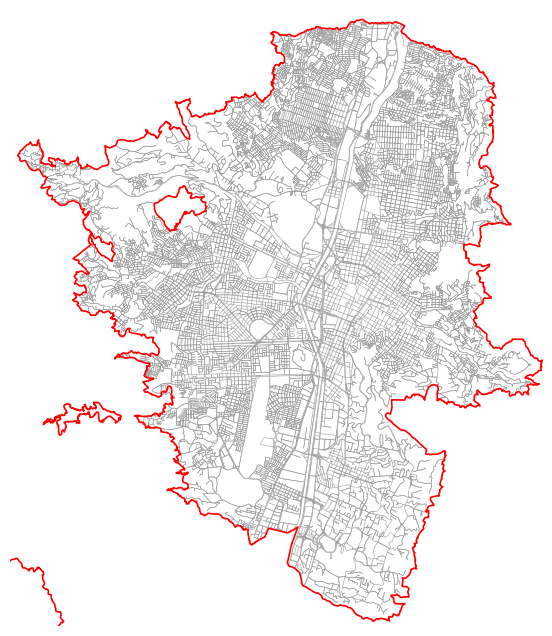

In [1]:
import geopandas as gpd
import osmnx as ox
import matplotlib.pyplot as plt
from pathlib import Path

def find_repo_root(start=Path.cwd()) -> Path:
    for candidate in [start.resolve(), *start.resolve().parents]:
        if (candidate / "edge_importance_ph").exists():
            return candidate
    raise FileNotFoundError(f"Could not find urban_form repository from {start.resolve()}")

REPO_ROOT = find_repo_root()
EDGE_IMPORTANCE_ROOT = REPO_ROOT / "edge_importance_ph"
ROAD_IMPORTANCE_DIR = EDGE_IMPORTANCE_ROOT / "calculate_road_importance"
MDE_FIGS_DIR = EDGE_IMPORTANCE_ROOT / "mde_road_importance_figs"
MDE_FIGS_DIR.mkdir(parents=True, exist_ok=True)

# Ruta al geojson del perímetro urbano
geojson_path = EDGE_IMPORTANCE_ROOT / "corcoran_replication" / "medellin_urban_perimeter" / "query.geojson"

# Leer el geojson
gdf = gpd.read_file(geojson_path)

# Revisar CRS y convertir a WGS84 si es necesario (OSMnx trabaja bien con EPSG:4326)
if gdf.crs is None:
    raise ValueError("El GeoJSON no tiene CRS definido. Asígnalo antes de continuar.")
if gdf.crs.to_epsg() != 4326:
    gdf = gdf.to_crs(epsg=4326)

# Unir todos los polígonos en una sola geometría
urban_geom = gdf.union_all()

# Descargar la red vial únicamente dentro del perímetro urbano
G = ox.graph_from_polygon(
    urban_geom,
    network_type="drive",
    simplify=True
)

# Graficar
fig, ax = ox.plot_graph(
    G,
    node_size=0,
    edge_linewidth=0.4,
    bgcolor="white",
    show=False,
    close=False
)

# Dibujar también el perímetro urbano encima
gpd.GeoSeries([urban_geom], crs="EPSG:4326").boundary.plot(
    ax=ax,
    color="red",
    linewidth=1.2
)

plt.show()

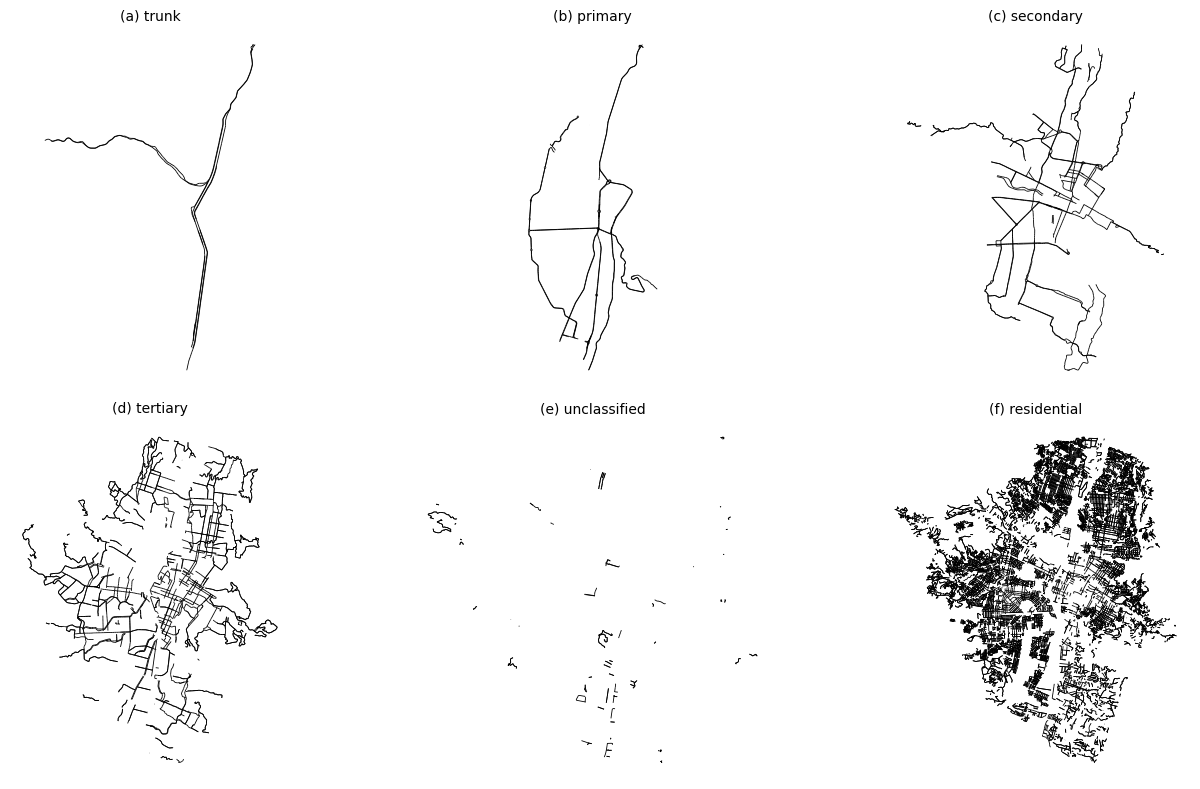

In [2]:
import geopandas as gpd
import osmnx as ox
import matplotlib.pyplot as plt

highway_order = [
    #"motorway",
    "trunk",
    "primary",
    "secondary",
    "tertiary",
    "unclassified",
    "residential",
]


# Convert to GeoDataFrame (edges only)
edges = ox.graph_to_gdfs(G, nodes=False)

# Some highways are stored as lists → normalize
edges["highway"] = edges["highway"].apply(
    lambda x: x[0] if isinstance(x, list) else x
)

# -----------------------------
# 3. PLOT EACH HIGHWAY TYPE
# -----------------------------
n = len(highway_order)
cols = 3
rows = int((n / cols) + 0.999)

fig, axes = plt.subplots(rows, cols, figsize=(14, 4 * rows))
axes = axes.flatten()

for i, hw in enumerate(highway_order):
    ax = axes[i]

    subset = edges[edges["highway"] == hw]

    if not subset.empty:
        subset.plot(
            ax=ax,
            linewidth=0.6,
            color="black",
        )

    ax.set_title(f"({chr(97+i)}) {hw}", fontsize=10)
    ax.set_axis_off()

# Remove extra axes if any
for j in range(i + 1, len(axes)):
    axes[j].set_visible(False)

plt.tight_layout()
plt.show()


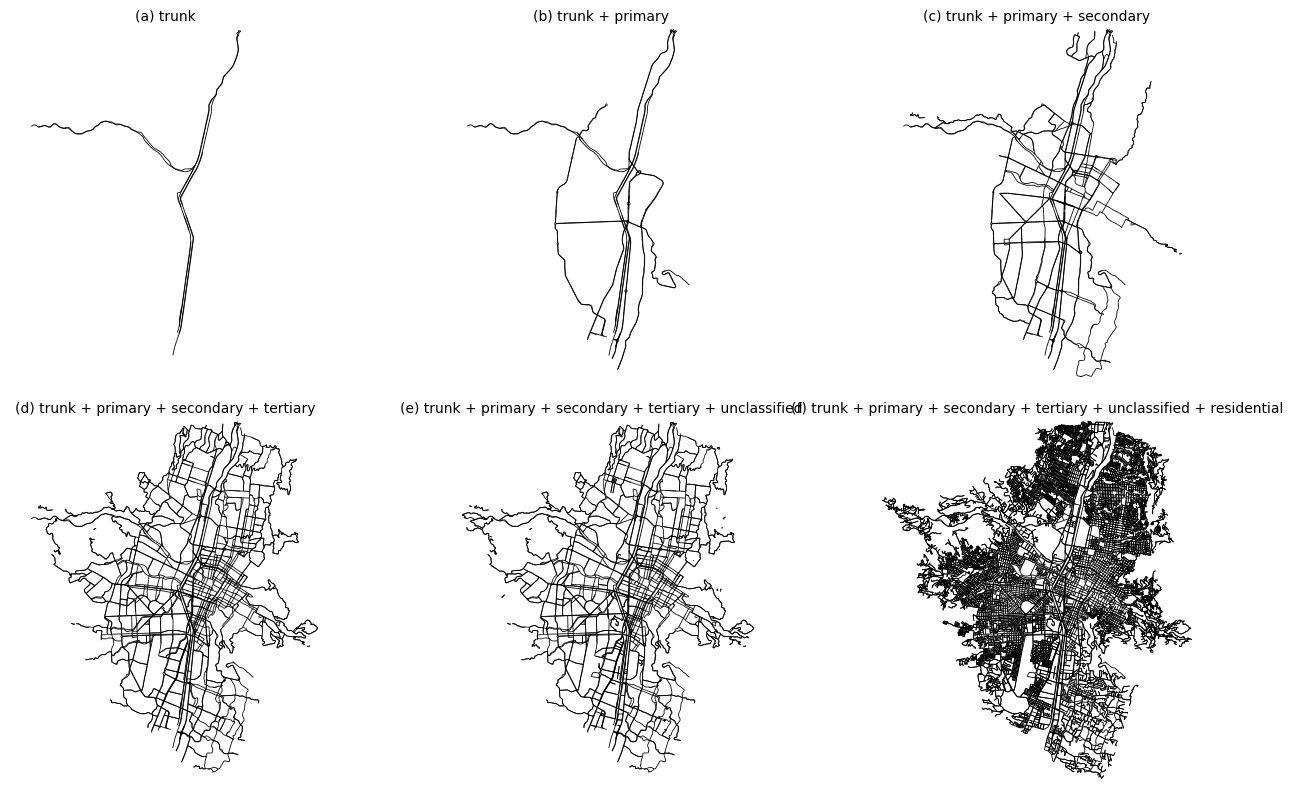

In [3]:
import numpy as np
edges = ox.graph_to_gdfs(G, nodes=False)

# Normalize highway field (handle list values)
edges["highway"] = edges["highway"].apply(
    lambda x: x[0] if isinstance(x, list) else x
)

# Fix global bounding box so all subplots match
xmin, ymin, xmax, ymax = edges.total_bounds

# -----------------------------
# PLOTTING
# -----------------------------
n = len(highway_order)
cols = 3
rows = int(np.ceil(n / cols))

fig, axes = plt.subplots(rows, cols, figsize=(14, 4 * rows))
axes = axes.flatten()

cumulative_types = []

for i, hw in enumerate(highway_order):

    cumulative_types.append(hw)

    ax = axes[i]

    subset = edges[edges["highway"].isin(cumulative_types)]

    if not subset.empty:
        subset.plot(
            ax=ax,
            linewidth=0.6,
            color="black",
        )

    ax.set_xlim(xmin, xmax)
    ax.set_ylim(ymin, ymax)

    title = " + ".join(cumulative_types)
    ax.set_title(f"({chr(97+i)}) {title}", fontsize=10)
    ax.set_axis_off()

# Hide unused axes
for j in range(i + 1, len(axes)):
    axes[j].set_visible(False)

plt.tight_layout()
plt.show()


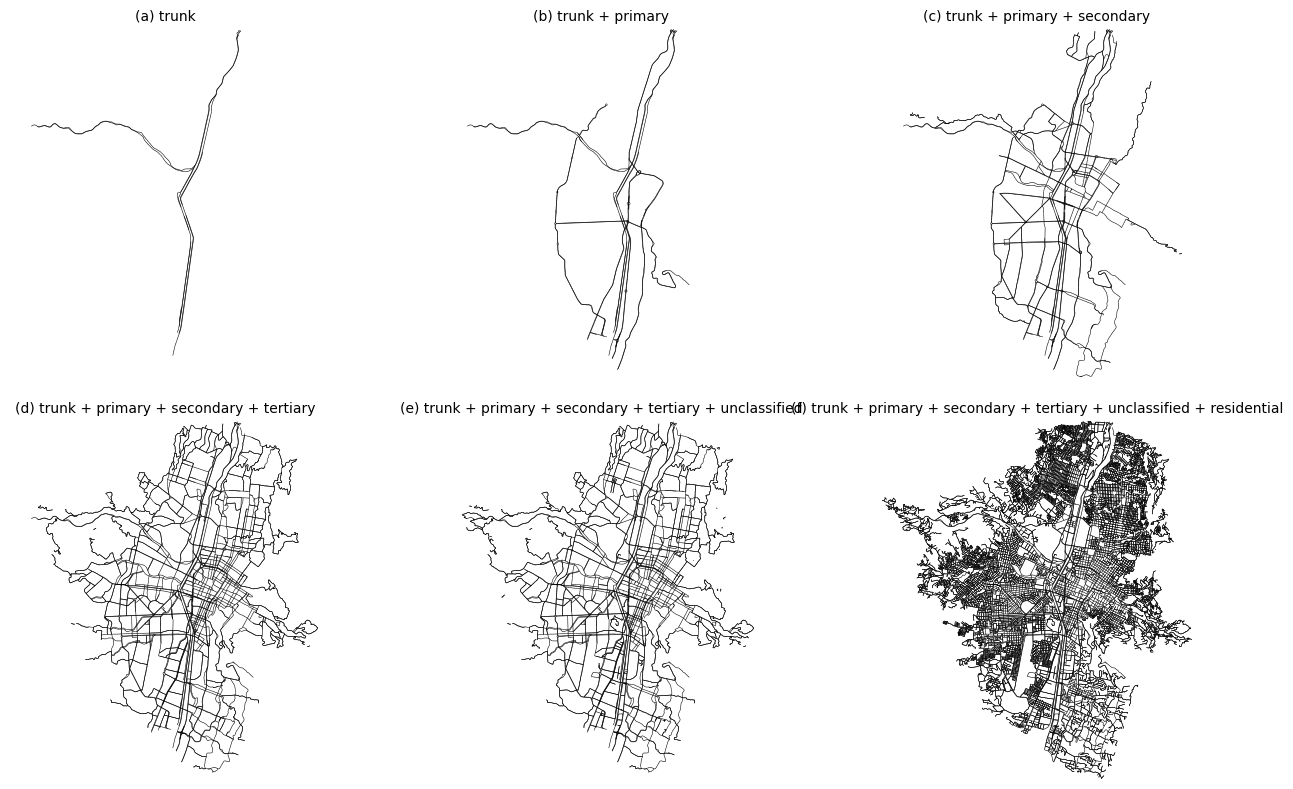

Final graph summary
Nodes: 15060
Edges: 21578

Simplex tree summary
Dimension: 1
Num vertices: 15060
Num simplices: 36638

Finite H1 intervals:
[]

Graph-theoretic diagnostics
Connected components: 6
Cycle rank: 6524

Betti numbers:
[6, 6524]


/opt/homebrew/anaconda3/envs/kernels/lib/python3.10/site-packages/gudhi/persistence_graphical_tools.py:129: UserWarning: usetex mode requires TeX.
  warnings.warn("usetex mode requires TeX.")


<Figure size 700x600 with 0 Axes>

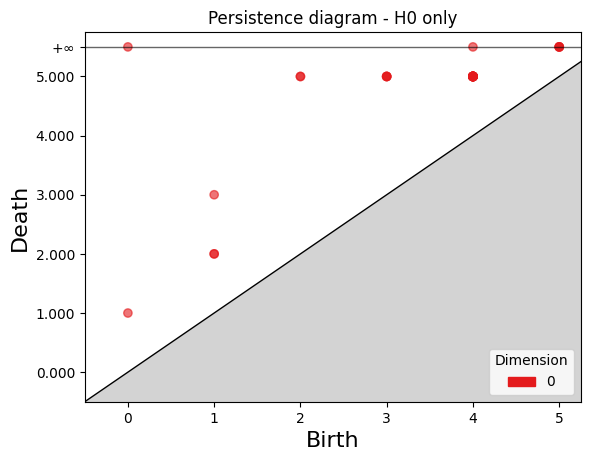

<Figure size 1000x400 with 0 Axes>

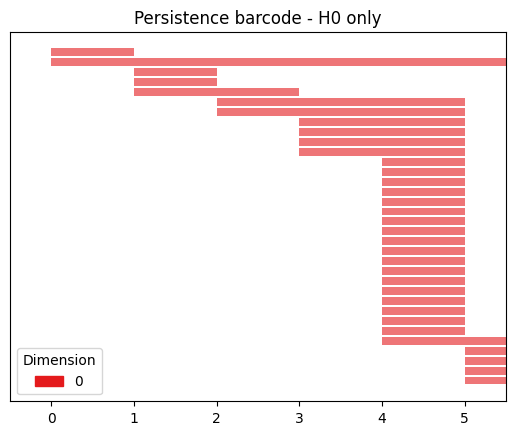

<Figure size 700x600 with 0 Axes>

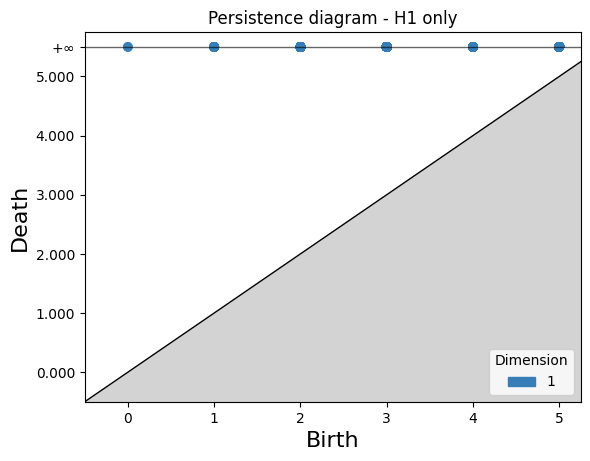

<Figure size 1000x400 with 0 Axes>

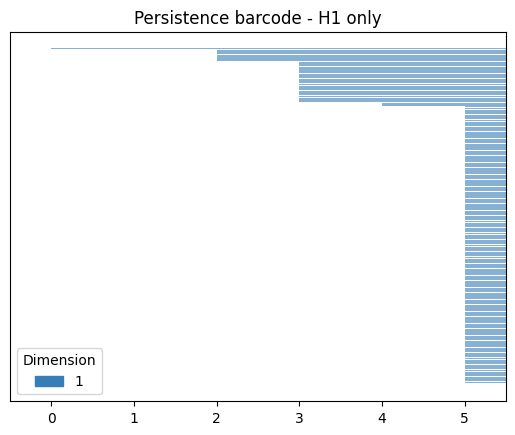


Step-by-step filtration summary

Step 0 -> ['trunk']
Nodes: 244
Edges: 246
Connected components: 2
Cycle rank: 4

Step 1 -> ['trunk', 'primary']
Nodes: 1073
Edges: 1107
Connected components: 4
Cycle rank: 38

Step 2 -> ['trunk', 'primary', 'secondary']
Nodes: 2898
Edges: 3159
Connected components: 4
Cycle rank: 265

Step 3 -> ['trunk', 'primary', 'secondary', 'tertiary']
Nodes: 6328
Edges: 7383
Connected components: 7
Cycle rank: 1062

Step 4 -> ['trunk', 'primary', 'secondary', 'tertiary', 'unclassified']
Nodes: 6488
Edges: 7574
Connected components: 26
Cycle rank: 1112

Step 5 -> ['trunk', 'primary', 'secondary', 'tertiary', 'unclassified', 'residential']
Nodes: 15060
Edges: 21578
Connected components: 6
Cycle rank: 6524


In [4]:
import osmnx as ox
import networkx as nx
import matplotlib.pyplot as plt
import numpy as np
import gudhi

filtration_time = {hw: i for i, hw in enumerate(highway_order)}

ox.settings.use_cache = True
ox.settings.log_console = True

# -----------------------------
# DOWNLOAD FULL NETWORK
# -----------------------------

edges = ox.graph_to_gdfs(G, nodes=False).copy()

# Normalize highway field
def normalize_highway(x):
    if isinstance(x, list):
        return x[0]
    return x

edges["highway"] = edges["highway"].apply(normalize_highway)

# Keep only classes used in the filtration
edges = edges[edges["highway"].isin(highway_order)].copy()

# Global bounds for plotting
xmin, ymin, xmax, ymax = edges.total_bounds

# -----------------------------
# PLOT FILTRATION SNAPSHOTS
# -----------------------------
n = len(highway_order)
cols = 3
rows = int(np.ceil(n / cols))

fig, axes = plt.subplots(rows, cols, figsize=(14, 4 * rows))
axes = axes.flatten()

cumulative_types = []

for i, hw in enumerate(highway_order):
    cumulative_types.append(hw)
    ax = axes[i]

    subset = edges[edges["highway"].isin(cumulative_types)]

    if not subset.empty:
        subset.plot(
            ax=ax,
            linewidth=0.4,
            color="black",
        )

    ax.set_xlim(xmin, xmax)
    ax.set_ylim(ymin, ymax)
    ax.set_title(f"({chr(97+i)}) " + " + ".join(cumulative_types), fontsize=10)
    ax.set_axis_off()

for j in range(i + 1, len(axes)):
    axes[j].set_visible(False)

plt.tight_layout()
plt.show()

# -----------------------------
# BUILD SIMPLE UNDIRECTED GRAPH
# -----------------------------
# Collapse the MultiDiGraph into a simple undirected graph.
# If multiple edges connect the same pair, keep the earliest filtration value.
H = nx.Graph()

for (u, v, k), row in edges.iterrows():
    hw = row["highway"]
    t = filtration_time[hw]

    if u == v:
        continue

    if H.has_edge(u, v):
        H[u][v]["filtration"] = min(H[u][v]["filtration"], t)
        prev_types = H[u][v].get("highway_types", set())
        prev_types.add(hw)
        H[u][v]["highway_types"] = prev_types
    else:
        H.add_edge(u, v, filtration=t, highway_types={hw})

print("Final graph summary")
print("Nodes:", H.number_of_nodes())
print("Edges:", H.number_of_edges())

# -----------------------------
# NODE FILTRATION
# -----------------------------
# Each node appears when its first incident edge appears.
node_filtration = {}
for node in H.nodes():
    incident_times = [H[node][nbr]["filtration"] for nbr in H.neighbors(node)]
    node_filtration[node] = min(incident_times) if incident_times else 0

# -----------------------------
# BUILD GUDHI SIMPLEX TREE
# -----------------------------
st = gudhi.SimplexTree()

# Reindex nodes to integers
node_to_int = {node: i for i, node in enumerate(H.nodes())}
int_to_node = {i: node for node, i in node_to_int.items()}

# Insert vertices
for node, t in node_filtration.items():
    st.insert([node_to_int[node]], filtration=float(t))

# Insert edges
for u, v, data in H.edges(data=True):
    st.insert([node_to_int[u], node_to_int[v]], filtration=float(data["filtration"]))

# IMPORTANT:
# Keep the complex 1-dimensional to study graph cycles directly.
# Do NOT call st.expansion(max_dim=2) unless you want the clique complex.

print("\nSimplex tree summary")
print("Dimension:", st.dimension())
print("Num vertices:", st.num_vertices())
print("Num simplices:", st.num_simplices())

# -----------------------------
# COMPUTE PERSISTENCE
# -----------------------------
# persistence_dim_max=True is crucial here because the complex is 1-dimensional
diag = st.persistence(
    homology_coeff_field=2,
    persistence_dim_max=True
)

h0 = st.persistence_intervals_in_dimension(0)
h1 = st.persistence_intervals_in_dimension(1)


# Finite H1 bars
h1_finite = h1[np.isfinite(h1).all(axis=1)] if len(h1) > 0 else np.empty((0, 2))
print("\nFinite H1 intervals:")
print(h1_finite)

if len(h1_finite) > 0:
    h1_lengths = h1_finite[:, 1] - h1_finite[:, 0]
    print("\nFinite H1 bar lengths:")
    print(h1_lengths)

# -----------------------------
# GRAPH-THEORETIC CHECK
# -----------------------------
# For a graph, cycle rank = m - n + c
c = nx.number_connected_components(H)
m = H.number_of_edges()
n_nodes = H.number_of_nodes()
cycle_rank = m - n_nodes + c

print("\nGraph-theoretic diagnostics")
print("Connected components:", c)
print("Cycle rank:", cycle_rank)

# -----------------------------
# BETTI NUMBERS
# -----------------------------
bettis = st.betti_numbers()
print("\nBetti numbers:")
print(bettis)



# -----------------------------
# PLOT H0 ONLY
# -----------------------------
if len(h0) > 0:
    h0_diag = [(0, (birth, death)) for birth, death in h0]

    plt.figure(figsize=(7, 6))
    gudhi.plot_persistence_diagram(h0_diag)
    plt.title("Persistence diagram - H0 only")
    plt.show()

    plt.figure(figsize=(10, 4))
    gudhi.plot_persistence_barcode(h0_diag)
    plt.title("Persistence barcode - H0 only")
    plt.show()
else:
    print("\nNo H0 intervals found.")

# -----------------------------
# PLOT H1 ONLY
# -----------------------------
if len(h1) > 0:
    h1_diag = [(1, (birth, death)) for birth, death in h1]

    plt.figure(figsize=(7, 6))
    gudhi.plot_persistence_diagram(h1_diag)
    plt.title("Persistence diagram - H1 only")
    plt.show()

    plt.figure(figsize=(10, 4))
    gudhi.plot_persistence_barcode(h1_diag)
    plt.title("Persistence barcode - H1 only")
    plt.show()
else:
    print("\nNo H1 intervals found.")

# -----------------------------
# STEP-BY-STEP FILTRATION CHECK
# -----------------------------
print("\nStep-by-step filtration summary")
for t in range(len(highway_order)):
    edges_t = [(u, v) for u, v, d in H.edges(data=True) if d["filtration"] <= t]
    G_t = nx.Graph()
    G_t.add_edges_from(edges_t)

    n_t = G_t.number_of_nodes()
    m_t = G_t.number_of_edges()
    c_t = nx.number_connected_components(G_t) if n_t > 0 else 0
    cycle_rank_t = m_t - n_t + c_t if n_t > 0 else 0

    print(f"\nStep {t} -> {highway_order[:t+1]}")
    print("Nodes:", n_t)
    print("Edges:", m_t)
    print("Connected components:", c_t)
    print("Cycle rank:", cycle_rank_t)



In [6]:
import numpy as np

replacement = len(highway_order) 

h0[np.isinf(h0)] = replacement
h1[np.isinf(h1)] = replacement

In [8]:
h0

array([[0., 1.],
       [1., 2.],
       [1., 2.],
       [1., 3.],
       [4., 5.],
       [4., 5.],
       [2., 5.],
       [4., 5.],
       [3., 5.],
       [4., 5.],
       [4., 5.],
       [4., 5.],
       [4., 5.],
       [4., 5.],
       [4., 5.],
       [3., 5.],
       [4., 5.],
       [3., 5.],
       [4., 5.],
       [4., 5.],
       [4., 5.],
       [4., 5.],
       [4., 5.],
       [3., 5.],
       [2., 5.],
       [4., 5.],
       [4., 5.],
       [4., 5.],
       [4., 6.],
       [5., 6.],
       [5., 6.],
       [5., 6.],
       [5., 6.],
       [0., 6.]])

6
6


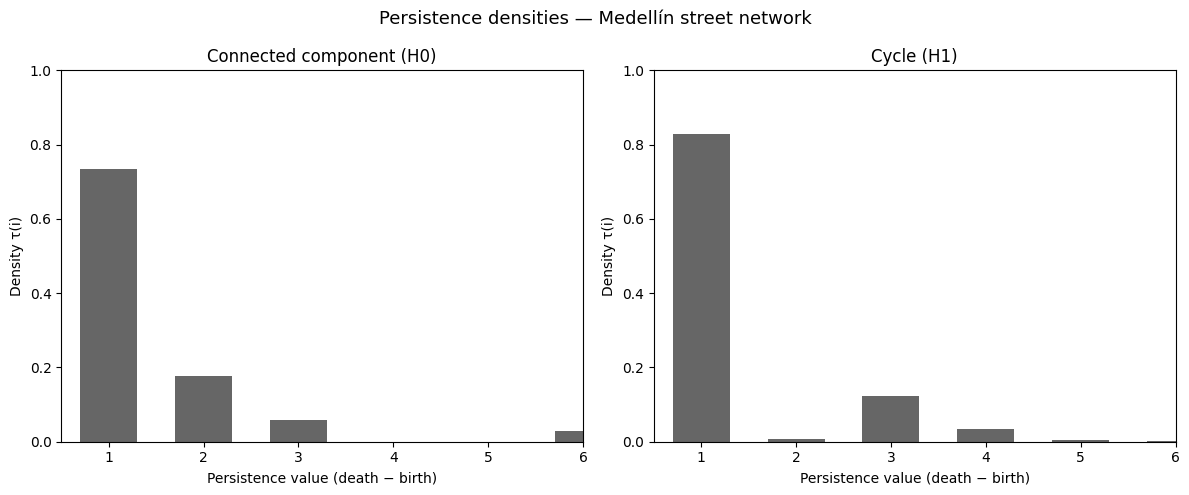

In [13]:
# -----------------------------
# PERSISTENCE DENSITY
# -----------------------------
def persistence_density(intervals, max_persistence=None):
    """
    Computes τ(i) = |{(p,q): (p,q) ∈ D, q-p = i}| / |D|
    for each integer persistence value i in [1, max_persistence].
    """
    finite = intervals[np.isfinite(intervals).all(axis=1)] if len(intervals) > 0 else np.empty((0, 2))
    if len(finite) == 0:
        return np.array([]), np.array([])

    lengths = (finite[:, 1] - finite[:, 0]).astype(int)
    total = len(finite)

    if max_persistence is None:
        max_persistence = int(lengths.max())
        print(max_persistence)

    i_values = np.arange(1, max_persistence + 1)
    density = np.array([np.sum(lengths == i) / total for i in i_values])
    return i_values, density


fig, axes = plt.subplots(1, 2, figsize=(12, 5))

for ax, (intervals, label, dim) in zip(axes, [
    (h0, "Connected component (H0)", "H0"),
    (h1, "Cycle (H1)",               "H1"),
]):
    i_vals, dens = persistence_density(intervals, max_persistence=None)
    if len(i_vals) == 0:
        ax.set_title(f"No finite {dim} intervals")
        continue
    ax.bar(i_vals, dens, color="#666666", width=0.6)
    ax.set_xlim(0.5, len(highway_order) - 0.5)
    ax.set_ylim(0, 1.0)
    ax.set_xticks(i_vals)
    ax.set_xlabel("Persistence value (death − birth)")
    ax.set_ylabel("Density τ(i)")
    ax.set_title(label)

plt.suptitle("Persistence densities — Medellín street network", fontsize=13)
plt.tight_layout()
plt.show()

In [28]:

import numpy as np
import osmnx as ox
import matplotlib.pyplot as plt
import matplotlib.cm as cm
import matplotlib.patches as mpatches
import networkx as nx

edges = ox.graph_to_gdfs(G, nodes=False)
edges["highway"] = edges["highway"].apply(lambda x: x[0] if isinstance(x, list) else x)

# High-contrast palette
DISTINCT_COMPONENT_COLORS = [
    "#0000ff", "#ff0000", "#00ff00", "#000033", "#ff00b6",
    "#005300", "#ffd300", "#009fff", "#9a4d42", "#00ffbe",
    "#783fc1", "#1f9698", "#f10dff", "#b1cc71", "#f1085c",
    "#fe8f42", "#dd00ff", "#201a01", "#720055", "#766c95",
]

def get_component_colors(n_components):
    if n_components <= len(DISTINCT_COMPONENT_COLORS):
        return DISTINCT_COMPONENT_COLORS[:n_components]
    fallback = cm.get_cmap("nipy_spectral", n_components)
    return [fallback(i) for i in range(n_components)]


def plot_connected_components_pdf(H, highway_types, filtration_time, filename, title):
    filename = Path(filename)
    filename.parent.mkdir(parents=True, exist_ok=True)
    edges_t = [
        (u, v) for u, v, d in H.edges(data=True)
        if d["filtration"] <= max(filtration_time[hw] for hw in highway_types)
    ]

    G_t = nx.Graph()
    G_t.add_edges_from(edges_t)

    components = sorted(nx.connected_components(G_t), key=len, reverse=True)
    n_components = len(components)

    print(f"{filename}: {n_components} components, {G_t.number_of_nodes()} nodes, {G_t.number_of_edges()} edges")

    nodes_gdf = ox.graph_to_gdfs(G, edges=False)
    pos = {
        node: (nodes_gdf.loc[node, "x"], nodes_gdf.loc[node, "y"])
        for node in G_t.nodes() if node in nodes_gdf.index
    }

    fig, ax = plt.subplots(figsize=(15, 12))

    if n_components == 0:
        ax.set_axis_off()
        ax.set_title(title, fontsize=14)
    else:
        colors = get_component_colors(n_components)

        node_to_comp = {}
        legend_handles = []

        for idx, comp in enumerate(components):
            legend_handles.append(
                mpatches.Patch(
                    facecolor=colors[idx],
                    edgecolor="black",
                    label=f"Component {idx + 1} ({len(comp)} nodes)",
                )
            )
            for node in comp:
                node_to_comp[node] = idx

        valid_edges = [(u, v) for u, v in G_t.edges() if u in pos and v in pos]

        # --- SPLIT edges by component size ---
        large_edges = []
        small_edges = []

        for u, v in valid_edges:
            comp_idx = node_to_comp[u]
            comp_size = len(components[comp_idx])

            if comp_size <= 10:
                small_edges.append((u, v))
            else:
                large_edges.append((u, v))

        # --- DRAW LARGE components (background) ---
        nx.draw_networkx_edges(
            G_t,
            pos,
            edgelist=large_edges,
            ax=ax,
            edge_color=[colors[node_to_comp[u]] for u, v in large_edges],
            width=1.0,
            alpha=0.7
        )

        # --- DRAW SMALL components (highlighted) ---
        nx.draw_networkx_edges(
            G_t,
            pos,
            edgelist=small_edges,
            ax=ax,
            edge_color=[colors[node_to_comp[u]] for u, v in small_edges],
            width=1.0,   # 🔥 thicker
            alpha=1.0
        )

        # --- DRAW NODES for small components ---
        small_nodes = [
            n for comp in components if len(comp) <= 10
            for n in comp if n in pos
        ]

        nx.draw_networkx_nodes(
            G_t,
            pos,
            nodelist=small_nodes,
            node_size=0.1,
            node_color=[colors[node_to_comp[n]] for n in small_nodes],
            ax=ax
        )

        # --- TEXT ---
        ax.text(
            0.02, 0.98, f"Connected components: {n_components}",
            transform=ax.transAxes, ha="left", va="top", fontsize=11,
            bbox=dict(boxstyle="round,pad=0.3", facecolor="white", edgecolor="black", alpha=0.9),
        )

        # --- LEGEND ---
        ax.legend(
            handles=legend_handles,
            title="Colors used",
            loc="upper left",
            bbox_to_anchor=(1.02, 1.0),
            borderaxespad=0.0,
            frameon=True,
            fontsize=8,
            title_fontsize=10,
            ncol=1 if n_components <= 10 else 2,
        )

        fig.subplots_adjust(right=0.75)

    ax.set_aspect("equal")
    ax.set_axis_off()
    ax.set_title(title, fontsize=14)

    fig.savefig(filename, format="pdf", bbox_inches="tight")
    plt.close(fig)

    print(f"Saved: {filename}")


# ---- RUN ----

plot_connected_components_pdf(
    H, ["trunk"], filtration_time,
    MDE_FIGS_DIR / "steps_mde" / "step_00_trunk.pdf", "Trunk - connected components"
)

plot_connected_components_pdf(
    H, ["trunk", "primary", "secondary", "tertiary", "unclassified","residential"], filtration_time,
    MDE_FIGS_DIR / "steps_mde" / "step_05_trunk_primary_secondary_tertiary_unclassified_residential.pdf", "Trunk + Primary - connected components"
)

steps_mde/step_00_trunk.pdf: 2 components, 244 nodes, 246 edges
Saved: steps_mde/step_00_trunk.pdf
steps_mde/step_05_trunk_primary_secondary_tertiary_unclassified_residential.pdf: 6 components, 15060 nodes, 21578 edges
Saved: steps_mde/step_05_trunk_primary_secondary_tertiary_unclassified_residential.pdf


In [ ]:
highway_order = [
    #"motorway",
    "trunk",
    "primary",
    "secondary",
    "tertiary",
    "unclassified",
    "residential",
]